Исследование данных

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pd_model.config import FEATURES, TARGET, STATUS_COLUMNS, BILL_COLUMNS, file_sha256, write_json
from pd_model.data.validation import load_csv, require_valid
from pd_model.features.build_features import CreditFeatureEngineer, feature_groups

ROOT = Path.cwd() if Path('params.yaml').exists() else Path.cwd().parent
FIGURES = ROOT / 'reports/figures/eda'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD = '#285A8E', '#B48324'
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=160)
    plt.show()
raw = load_csv(ROOT / 'data/raw/UCI_Credit_Card.csv')
train = load_csv(ROOT / 'data/processed/train.csv')
test = load_csv(ROOT / 'data/processed/test.csv')
validation = require_valid(raw, 'raw')
print('GX success:', validation['success'])
print('SHA-256:', file_sha256(ROOT / 'data/raw/UCI_Credit_Card.csv'))
print('Raw / train / test:', raw.shape, train.shape, test.shape)

Matplotlib is building the font cache; this may take a moment.



Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]


Calculating Metrics:   0%|          | 0/228 [00:00<?, ?it/s]


Calculating Metrics:   1%|          | 2/228 [00:00<00:00, 2217.45it/s]


Calculating Metrics:   1%|          | 2/228 [00:00<00:00, 1156.09it/s]

...


Calculating Metrics: 100%|██████████| 228/228 [00:00<00:00, 4210.91it/s]


Calculating Metrics: 100%|██████████| 228/228 [00:00<00:00, 4153.39it/s]


Calculating Metrics: 100%|██████████| 228/228 [00:00<00:00, 4140.50it/s]


Calculating Metrics: 100%|██████████| 228/228 [00:00<00:00, 4123.85it/s]

GX success: True
SHA-256: a0f0ab49d6326671d6cd83be5c88dcf18007025fe9a53ecd699119c871176ca1
Raw / train / test: (30000, 25) (23999, 26) (6001, 26)


## Аудит snapshot и контроль разбиения

ID сохраняется для аудита и исключён из признаков модели.

In [2]:
raw_groups = feature_groups(raw[FEATURES])
group_labels = pd.DataFrame({'group': raw_groups, 'target': raw[TARGET]}).groupby('group')['target'].nunique()
audit = {
    'rows': len(raw), 'columns': len(raw.columns),
    'missing_cells': int(raw.isna().sum().sum()),
    'unique_ids': bool(raw.ID.is_unique),
    'exact_duplicates': int(raw.duplicated().sum()),
    'duplicates_without_id': int(raw.drop(columns='ID').duplicated().sum()),
    'duplicates_X_raw': int(raw[FEATURES].duplicated().sum()),
    'duplicates_X_normalized': int(raw_groups.duplicated().sum()),
    'normalized_groups_conflicting_targets': int((group_labels > 1).sum()),
    'negative_bill_cells': int((raw[BILL_COLUMNS] < 0).sum().sum()),
    'source_positive_rate': float(raw[TARGET].mean()),
    'train_rows': len(train), 'test_rows': len(test),
    'train_positive_rate': float(train[TARGET].mean()),
    'test_positive_rate': float(test[TARGET].mean()),
    'id_overlap': len(set(train.ID) & set(test.ID)),
    'group_overlap': len(set(train.feature_group) & set(test.feature_group)),
}
assert audit['id_overlap'] == audit['group_overlap'] == 0
write_json(ROOT / 'reports/eda_summary.json', audit)
display(pd.Series(audit, name='value').to_frame())

,value
rows,30000
columns,25
missing_cells,0
unique_ids,True
exact_duplicates,0
duplicates_without_id,35
duplicates_X_raw,56
duplicates_X_normalized,56
normalized_groups_conflicting_targets,21
negative_bill_cells,3932


Повторяющиеся входы с разными target сохранены: у разных клиентов может совпадать профиль. Все одинаковые нормализованные входы попадают в одну группу. Поэтому они не пересекают границы train/test и CV.

Отрицательные суммы счетов допустимы; их нельзя автоматически заменять нулём. Коды `EDUCATION=0/4/5/6`, `MARRIAGE=0`, `PAY=-2/-1/0` учитываются явно.

In [3]:
display(train[['AGE', 'LIMIT_BAL'] + BILL_COLUMNS + ['PAY_AMT1']].describe().T)
display(pd.DataFrame({column: train[column].value_counts().sort_index() for column in ['SEX','EDUCATION','MARRIAGE']}).fillna(0).astype(int))

,count,mean,std,min,25%,50%,75%,max
AGE,23999.0,35.483895,9.234510,21.0,28.0,34.0,41.0,79.0
LIMIT_BAL,23999.0,167156.951540,129869.525079,10000.0,50000.0,140000.0,240000.0,800000.0
BILL_AMT1,23999.0,51063.312221,72954.879816,-165580.0,3640.0,22591.0,66915.5,746814.0
BILL_AMT2,23999.0,49047.949206,70643.561840,-69777.0,3046.0,21351.0,63489.5,743970.0
BILL_AMT3,23999.0,47006.722530,69241.248626,-157264.0,2821.0,20207.0,60031.5,1664089.0
BILL_AMT4,23999.0,43177.829035,63848.995702,-170000.0,2350.0,19125.0,54235.5,706864.0
BILL_AMT5,23999.0,40290.279637,60377.188615,-61372.0,1807.5,18123.0,50246.0,587067.0
BILL_AMT6,23999.0,38855.878953,59418.825922,-339603.0,1288.0,17082.0,49205.5,699944.0
PAY_AMT1,23999.0,5667.278637,16646.616273,0.0,1000.0,2100.0,5006.0,873552.0


,SEX,EDUCATION,MARRIAGE
0,0,12,47
1,9546,8458,10937
2,14453,11247,12770
3,0,3912,245
4,0,104,0
5,0,224,0
6,0,42,0


## Баланс классов на train

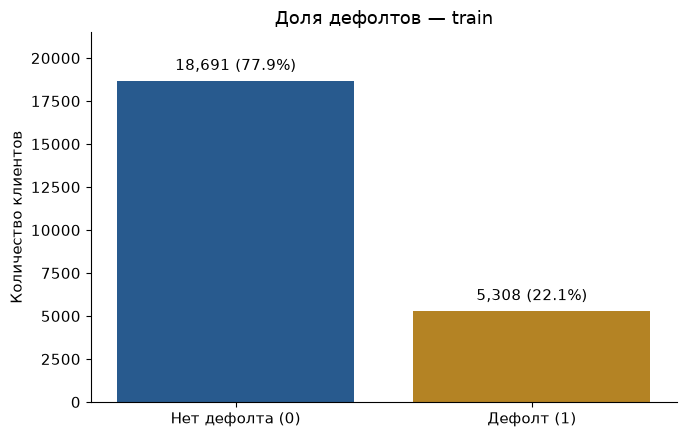

Train positive rate: 22.1176%; accuracy alone is insufficient.


In [4]:
counts = train[TARGET].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(['Нет дефолта (0)', 'Дефолт (1)'], counts, color=[BLUE, GOLD])
ax.bar_label(bars, labels=[f'{n:,} ({n / len(train):.1%})' for n in counts], padding=5)
ax.set(ylabel='Количество клиентов', title='Доля дефолтов - train', ylim=(0, counts.max() * 1.15))
save_figure(fig, 'class_balance')
print(f'Train positive rate: {train[TARGET].mean():.4%}; accuracy alone is insufficient.')

## Возраст и кредитный лимит

Логарифмическая шкала лимита показывает широкий диапазон сумм. Гистограммы описывают train.

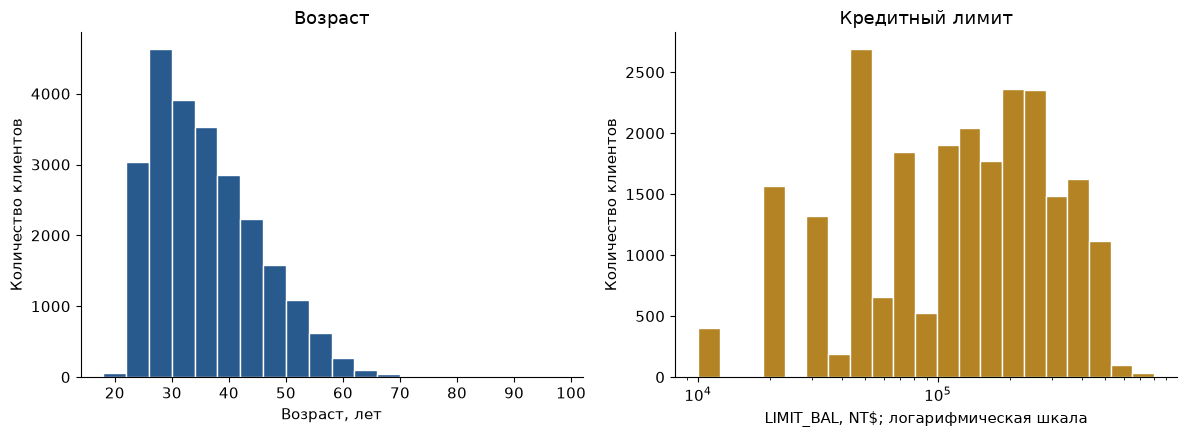

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(train.AGE, bins=np.arange(18, 102, 4), color=BLUE, edgecolor='white')
axes[0].set(title='Возраст', xlabel='Возраст, лет', ylabel='Количество клиентов')
axes[1].hist(train.LIMIT_BAL, bins=np.geomspace(train.LIMIT_BAL.min(), train.LIMIT_BAL.max(), 22), color=GOLD, edgecolor='white')
axes[1].set(xscale='log', title='Кредитный лимит', xlabel='LIMIT_BAL, NT$; логарифмическая шкала', ylabel='Количество клиентов')
save_figure(fig, 'age_limit')

## Последний статус платежа и дефолт

Наблюдаемая связь не доказывает причинность. PAY_0 - сентябрь; PAY_2…PAY_6 - август…апрель.

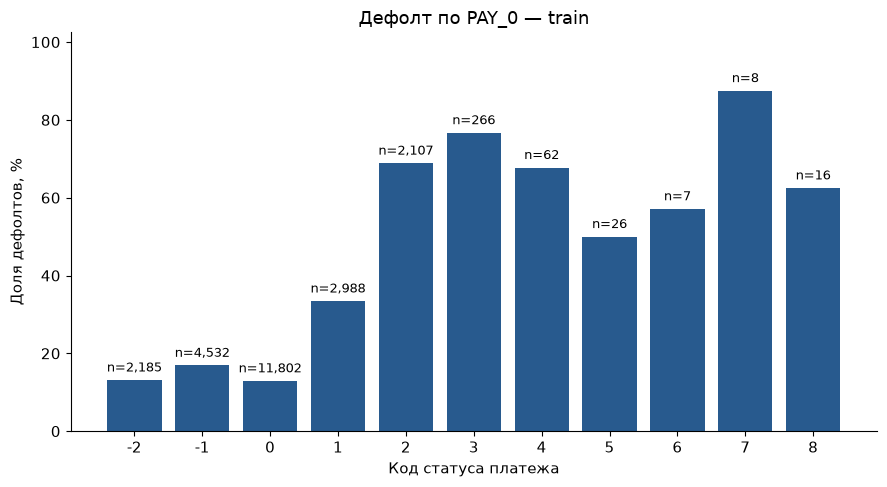

,default_rate,clients
PAY_0,,
-2,0.131350,2185
-1,0.169020,4532
0,0.129215,11802
1,0.334337,2988
2,0.688657,2107
3,0.766917,266
4,0.677419,62
5,0.500000,26
6,0.571429,7


In [6]:
status = train.groupby('PAY_0')[TARGET].agg(['mean','count']).sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(status.index.astype(str), status['mean'] * 100, color=BLUE)
ax.bar_label(bars, labels=[f'n={n:,}' for n in status['count']], fontsize=9, padding=4)
ax.set(title='Дефолт по PAY_0 - train', xlabel='Код статуса платежа', ylabel='Доля дефолтов, %', ylim=(0, min(105, status['mean'].max()*100+15)))
save_figure(fig, 'pay_status_default')
display(status.rename(columns={'mean':'default_rate','count':'clients'}))

## Корреляции числовых историй

Высокая корреляция соседних счетов мотивирует агрегаты; это не основание для отбора по test.

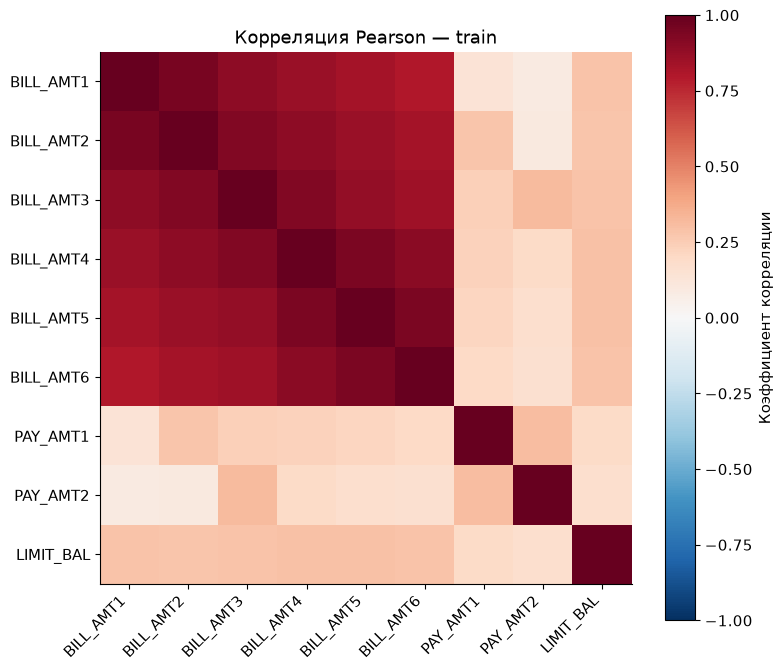

In [7]:
columns = BILL_COLUMNS + ['PAY_AMT1', 'PAY_AMT2', 'LIMIT_BAL']
corr = train[columns].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(columns)), columns, rotation=45, ha='right')
ax.set_yticks(range(len(columns)), columns)
ax.set_title('Корреляция Pearson - train')
fig.colorbar(im, ax=ax, label='Коэффициент корреляции')
save_figure(fig, 'correlation')

## Проверка признаков

Pipeline создаёт агрегаты задержек, сумм счетов и платежей, отношения к лимиту и сумму платежей к положительным счетам. Возрастная группа имеет фиксированные границы. Нулевой знаменатель даёт NaN и индикатор; Imputer обучается отдельно в каждом train-fold.

In [8]:
engineer = CreditFeatureEngineer(use_aggregates=True)
features = engineer.fit_transform(train[FEATURES])
added = [name for name in features.columns if name not in FEATURES]
print('Added features:', added)
display(features[added].head())
assert 'ID' not in features and TARGET not in features
assert features.index.equals(train.index)
assert not np.isinf(features.select_dtypes(include='number')).any().any()

Added features: ['max_delay', 'delayed_months_count', 'recent_delay', 'bill_mean', 'bill_std', 'bill_max', 'payment_sum', 'payment_mean', 'bill_change_recent_old', 'limit_utilization_recent', 'payment_to_positive_bill_sum', 'zero_positive_bill_sum', 'age_group']


,max_delay,delayed_months_count,recent_delay,bill_mean,bill_std,bill_max,payment_sum,payment_mean,bill_change_recent_old,limit_utilization_recent,payment_to_positive_bill_sum,zero_positive_bill_sum,age_group
0,2,2,2,1284.000000,1608.143754,3913.0,689.0,114.833333,3913.0,0.195650,0.089434,0,18-29
1,2,2,0,2846.166667,582.382296,3455.0,5000.0,833.333333,-579.0,0.022350,0.292791,0,18-29
2,0,0,0,16942.166667,5536.122723,29239.0,11018.0,1836.333333,13690.0,0.324878,0.108388,0,30-44
3,0,0,0,38555.666667,9645.205746,49291.0,8388.0,1398.000000,17443.0,0.939800,0.036259,0,30-44
4,0,0,0,18223.166667,9739.045734,35835.0,59049.0,9841.500000,-10514.0,0.172340,0.540054,0,45-59


## Решения для обучения

1. Использовать все 23 исходных признака, исключив ID и target.
2. Сравнить исходные и дополненные признаки на одинаковых train CV folds.
3. Использовать ROC-AUC для выбора модели; Precision, Recall, F1 считать при заранее фиксированном пороге 0.5.
4. Отдельно показать PR-AUC и Brier score: ранжирование и качество вероятностей - разные свойства.
5. Итоговые значения и графики test находятся в `reports/metrics/test_metrics.json` и `reports/figures/evaluation/`.